In [1]:
from model import VAE_Encoder_MNIST,Ganerator_MNIST
import torch
from torchvision import datasets, transforms
from torchvision.utils import save_image
from pytorch_msssim import ssim
import numpy as np
import matplotlib.pyplot as plt
from com_utils import array_to_bits,quantization,dequantization,bits_to_array, lloyd_max
import os
from scipy.io import savemat, loadmat

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.FashionMNIST(
    root="D:/Python/SemCom/saved_data",
    train=True,
    download=False,
    transform=transform
)

# dataloader
dl = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=False)

# fixed_x, _ = next(iter(dl))
# fixed_x = fixed_x[:64].to(device)


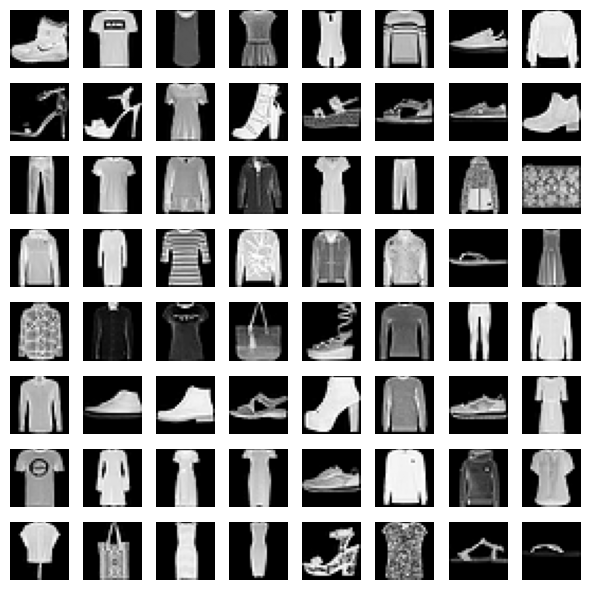

In [3]:
# original data
plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    plt.imshow(fixed_x[i].cpu().squeeze().numpy(), cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# encoder
z_dim = 64
E = VAE_Encoder_MNIST(latent_dim=z_dim).to(device)
E.load_state_dict(torch.load("./save_model/E_invert_to_G_F.pth"))
E.eval()
for p in E.parameters():
    p.requires_grad = False
    
G = Ganerator_MNIST(z_dim=z_dim).to(device)
G.load_state_dict(torch.load("./save_model/G_wgangp_C.pth"))
G.eval()
for p in G.parameters():
    p.requires_grad = False

In [6]:
# encode
with torch.no_grad():
    mu, logvar = E(fixed_x)
    fixed_z = mu

# 存 latent
z_np = fixed_z.detach().cpu().numpy()
# np.save("z_batch.npy", z_np)

print("z shape =", fixed_z.shape)
print("z =", fixed_z)

z shape = torch.Size([64, 64])
z = tensor([[-0.0609,  0.5086,  1.4428,  ...,  1.3850,  1.6067, -1.6071],
        [-1.4115,  1.3989,  0.1375,  ...,  0.4019,  1.5869,  0.3517],
        [-0.2585, -0.2100,  0.3494,  ...,  0.2614, -0.1765, -0.6236],
        ...,
        [-0.4697,  1.2713, -0.5302,  ...,  0.4834, -0.2818,  0.1444],
        [-0.7918,  0.1833,  0.5184,  ...,  2.4927, -0.8237, -0.1044],
        [-0.2623, -0.8020, -0.1092,  ...,  2.8318, -0.2851, -0.9773]],
       device='cuda:0')


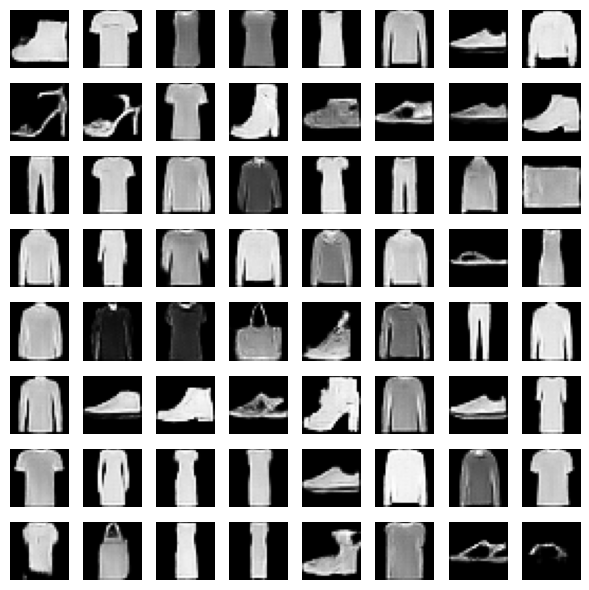

In [7]:
z_in = fixed_z.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
# reconstruct
with torch.no_grad():
    x_gen_orig = G(z_in)

plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    img = ((x_gen_orig[i] + 1) / 2).cpu().squeeze().numpy()
    plt.imshow(img, cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

save_image((x_gen_orig.cpu() + 1) / 2, "./save_data/lloyd_max_codebook/gen_x_f.png", nrow=8)

In [12]:
# 這裡停在測試完VAE encoder 做完 encode 
# 做量化
# 做復原然後做量化前後對比
# 解決問題:
#   1. transformer的不同會造成解出的結果有誤差
#   2. 有無normalization也有差
# 待解決: 
#   1. 要不要對gan也新增label來提升encoder對於 decode的結果做提升，畢竟DM都需要label了
#      是否passdown 的差別而已
# 2026.03.11

In [8]:
# 統計經過encode後的數據
# 1.先統計每個data經過code之後的數據
# 2.做8 bits(256)、7 bits(128)、6 bits(64)、5 bits(32)的uniform quantization
all_z = []

E.eval()

with torch.no_grad():
    for x, _ in dl:

        x = x.to(device)

        mu, logvar = E(x)   # VAE encoder
        z = mu              # 通常 encode 用 mean

        all_z.append(z.cpu())

all_z = torch.cat(all_z, dim=0)

print("latent shape:", all_z.shape)
print("min:", all_z.min())
print("max:", all_z.max())
print("mean:", all_z.mean())
print("std:", all_z.std())

latent shape: torch.Size([60000, 64])
min: tensor(-6.8110)
max: tensor(7.0037)
mean: tensor(-0.0375)
std: tensor(0.9784)


In [18]:
i = 50
for j in range (1,9):
    bits = j
    # b_list = []
    # q_list = []
    # test_iter = [50,70,100,120]
    # for i in test_iter:
    q,b = lloyd_max (all_z, max_iter=i, K=2**bits)
    # b_list.append(b)
    # q_list.append(q)
    print(f"boundaries (iter={i}):")
    print(b)
    # # print(b_list)
    torch.save({
        "q": q,
        "b": b,
    }, f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}_f.pth")

boundaries (iter=50):
tensor([-0.0324])
boundaries (iter=50):
tensor([-1.0493, -0.0488,  0.9497])
boundaries (iter=50):
tensor([-2.0084, -1.1619, -0.5734, -0.0603,  0.4495,  1.0198,  1.7887])
boundaries (iter=50):
tensor([-3.6230e+00, -2.5708e+00, -1.9380e+00, -1.4559e+00, -1.0498e+00,
        -6.8447e-01, -3.3936e-01, -2.5117e-03,  3.3291e-01,  6.7394e-01,
         1.0299e+00,  1.4142e+00,  1.8449e+00,  2.3510e+00,  3.0647e+00])
boundaries (iter=50):
tensor([-5.6848, -5.0950, -4.5196, -3.9799, -3.5018, -3.0696, -2.6734, -2.3076,
        -1.9653, -1.6425, -1.3376, -1.0477, -0.7688, -0.4969, -0.2282,  0.0401,
         0.3092,  0.5812,  0.8579,  1.1411,  1.4343,  1.7382,  2.0504,  2.3702,
         2.7027,  3.0592,  3.4552,  3.9157,  4.4551,  5.0464,  5.9614])
boundaries (iter=50):
tensor([-6.5629, -6.2982, -6.0561, -5.8346, -5.6127, -5.3982, -5.1774, -4.9342,
        -4.6864, -4.4381, -4.1888, -3.9455, -3.7139, -3.4874, -3.2611, -3.0373,
        -2.8192, -2.6067, -2.3973, -2.1907, -1.986

{'q': tensor([-0.7942,  0.7293]), 'b': tensor([-0.0324])}
tensor([-0.0324])


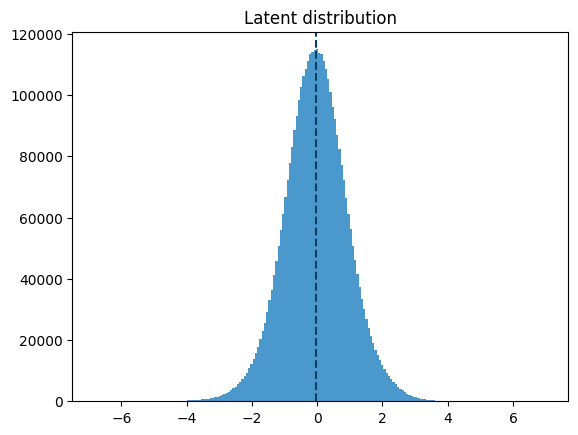

{'q': tensor([-1.6000, -0.4986,  0.4010,  1.4984]), 'b': tensor([-1.0493, -0.0488,  0.9497])}
tensor([-1.0493, -0.0488,  0.9497])


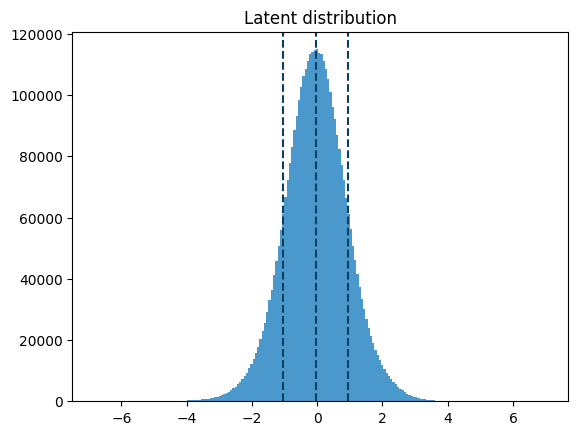

{'q': tensor([-2.5302, -1.4866, -0.8376, -0.3099,  0.1883,  0.7094,  1.3285,  2.2472]), 'b': tensor([-2.0084, -1.1619, -0.5734, -0.0603,  0.4495,  1.0198,  1.7887])}
tensor([-2.0084, -1.1619, -0.5734, -0.0603,  0.4495,  1.0198,  1.7887])


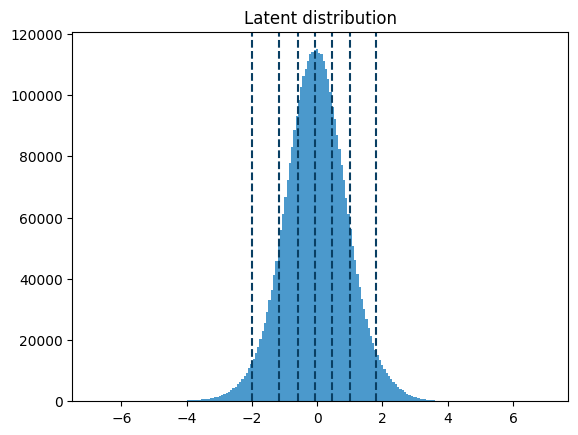

{'q': tensor([-4.2845, -2.9227, -2.1921, -1.6629, -1.2324, -0.8555, -0.5062, -0.1696,
         0.1630,  0.4966,  0.8404,  1.2036,  1.6038,  2.0602,  2.6132,  3.4841]), 'b': tensor([-3.6230e+00, -2.5708e+00, -1.9380e+00, -1.4559e+00, -1.0498e+00,
        -6.8447e-01, -3.3936e-01, -2.5117e-03,  3.3291e-01,  6.7394e-01,
         1.0299e+00,  1.4142e+00,  1.8449e+00,  2.3510e+00,  3.0647e+00])}
tensor([-3.6230e+00, -2.5708e+00, -1.9380e+00, -1.4559e+00, -1.0498e+00,
        -6.8447e-01, -3.3936e-01, -2.5117e-03,  3.3291e-01,  6.7394e-01,
         1.0299e+00,  1.4142e+00,  1.8449e+00,  2.3510e+00,  3.0647e+00])


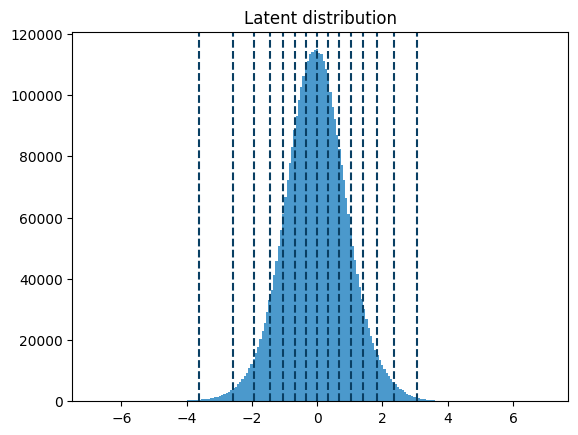

{'q': tensor([-5.9848, -5.3681, -4.7825, -4.2064, -3.7035, -3.2547, -2.8446, -2.4686,
        -2.1182, -1.7881, -1.4770, -1.1827, -0.9011, -0.6282, -0.3605, -0.0939,
         0.1731,  0.4412,  0.7140,  0.9910,  1.2766,  1.5734,  1.8805,  2.1947,
         2.5169,  2.8556,  3.2245,  3.6366,  4.1375,  4.7241,  5.3348,  6.5740]), 'b': tensor([-5.6848, -5.0950, -4.5196, -3.9799, -3.5018, -3.0696, -2.6734, -2.3076,
        -1.9653, -1.6425, -1.3376, -1.0477, -0.7688, -0.4969, -0.2282,  0.0401,
         0.3092,  0.5812,  0.8579,  1.1411,  1.4343,  1.7382,  2.0504,  2.3702,
         2.7027,  3.0592,  3.4552,  3.9157,  4.4551,  5.0464,  5.9614])}
tensor([-5.6848, -5.0950, -4.5196, -3.9799, -3.5018, -3.0696, -2.6734, -2.3076,
        -1.9653, -1.6425, -1.3376, -1.0477, -0.7688, -0.4969, -0.2282,  0.0401,
         0.3092,  0.5812,  0.8579,  1.1411,  1.4343,  1.7382,  2.0504,  2.3702,
         2.7027,  3.0592,  3.4552,  3.9157,  4.4551,  5.0464,  5.9614])


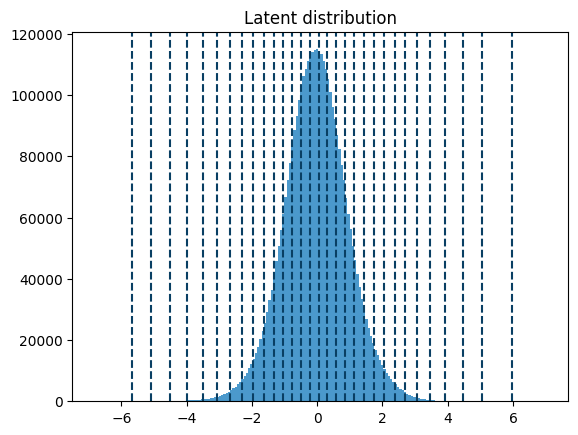

{'q': tensor([-6.6978, -6.4280, -6.1613, -5.9368, -5.7218, -5.4992, -5.2938, -5.0547,
        -4.8055, -4.5580, -4.3073, -4.0583, -3.8187, -3.5935, -3.3669, -3.1415,
        -2.9190, -2.7052, -2.4945, -2.2875, -2.0820, -1.8801, -1.6807, -1.4848,
        -1.2937, -1.1072, -0.9230, -0.7411, -0.5605, -0.3808, -0.2009, -0.0207,
         0.1598,  0.3407,  0.5227,  0.7057,  0.8898,  1.0762,  1.2658,  1.4589,
         1.6548,  1.8523,  2.0491,  2.2458,  2.4417,  2.6395,  2.8411,  3.0440,
         3.2608,  3.4810,  3.7222,  3.9798,  4.2463,  4.5175,  4.7845,  5.0376,
         5.3510,  5.6751,  5.9073,  6.1118,  6.3459,  6.6066,  6.7844,  7.0037]), 'b': tensor([-6.5629, -6.2982, -6.0561, -5.8346, -5.6127, -5.3982, -5.1774, -4.9342,
        -4.6864, -4.4381, -4.1888, -3.9455, -3.7139, -3.4874, -3.2611, -3.0373,
        -2.8192, -2.6067, -2.3973, -2.1907, -1.9865, -1.7853, -1.5872, -1.3933,
        -1.2040, -1.0181, -0.8344, -0.6527, -0.4720, -0.2916, -0.1111,  0.0699,
         0.2512,  0.4332,  

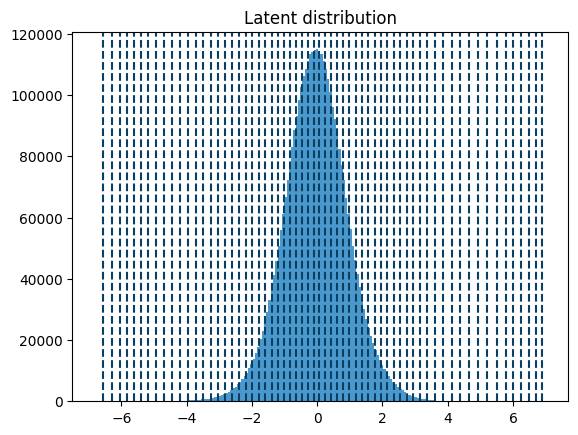

{'q': tensor([-6.8110, -6.6828, -6.5825, -6.4785, -6.3895, -6.2659, -6.1534, -6.0354,
        -5.9289, -5.8302, -5.7297, -5.6143, -5.5005, -5.3923, -5.2705, -5.1460,
        -5.0424, -4.9346, -4.8374, -4.7341, -4.6187, -4.5011, -4.3794, -4.2574,
        -4.1313, -4.0176, -3.9019, -3.7872, -3.6719, -3.5597, -3.4500, -3.3424,
        -3.2348, -3.1252, -3.0158, -2.9057, -2.7961, -2.6874, -2.5806, -2.4731,
        -2.3668, -2.2593, -2.1506, -2.0429, -1.9357, -1.8284, -1.7218, -1.6156,
        -1.5099, -1.4054, -1.3007, -1.1967, -1.0927, -0.9889, -0.8860, -0.7837,
        -0.6814, -0.5792, -0.4770, -0.3751, -0.2729, -0.1707, -0.0678,  0.0351,
         0.1376,  0.2400,  0.3424,  0.4449,  0.5478,  0.6511,  0.7543,  0.8580,
         0.9626,  1.0665,  1.1708,  1.2758,  1.3814,  1.4869,  1.5936,  1.7007,
         1.8083,  1.9151,  2.0212,  2.1266,  2.2320,  2.3380,  2.4426,  2.5478,
         2.6528,  2.7585,  2.8669,  2.9738,  3.0807,  3.1895,  3.2978,  3.4056,
         3.5179,  3.6303,  3.7533,

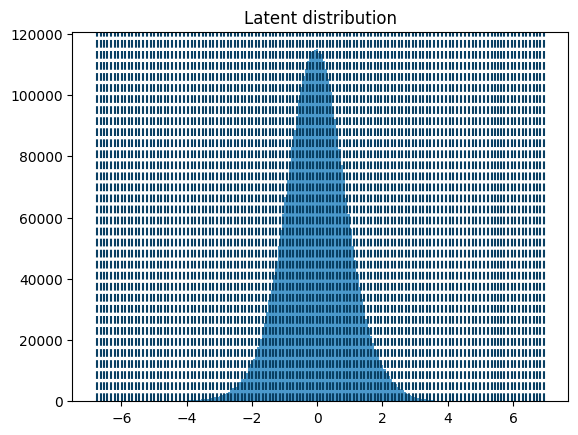

{'q': tensor([-6.8110, -6.7568, -6.6828, -6.6485, -6.6145, -6.5505, -6.4832, -6.4307,
        -6.3763, -6.3265, -6.2638, -6.2132, -6.1510, -6.0918, -6.0479, -5.9994,
        -5.9395, -5.8898, -5.8232, -5.7672, -5.7168, -5.6612, -5.6113, -5.5576,
        -5.5025, -5.4491, -5.3978, -5.3477, -5.2943, -5.2347, -5.1728, -5.1218,
        -5.0673, -5.0149, -4.9563, -4.9006, -4.8412, -4.7860, -4.7403, -4.6861,
        -4.6395, -4.5906, -4.5388, -4.4883, -4.4316, -4.3756, -4.3183, -4.2664,
        -4.2076, -4.1461, -4.0911, -4.0322, -3.9776, -3.9262, -3.8703, -3.8165,
        -3.7626, -3.7046, -3.6447, -3.5899, -3.5381, -3.4853, -3.4337, -3.3797,
        -3.3265, -3.2740, -3.2226, -3.1675, -3.1108, -3.0567, -3.0002, -2.9436,
        -2.8907, -2.8363, -2.7827, -2.7298, -2.6749, -2.6196, -2.5650, -2.5112,
        -2.4566, -2.4031, -2.3490, -2.2943, -2.2399, -2.1845, -2.1293, -2.0756,
        -2.0213, -1.9678, -1.9142, -1.8603, -1.8064, -1.7524, -1.6988, -1.6443,
        -1.5896, -1.5352, -1.4811,

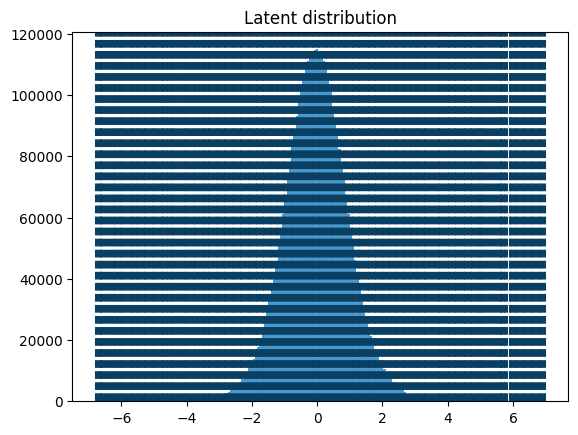

In [19]:
for i in range(1,9):
    bits = i
    lloyd_max_codebook = torch.load(f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}_f.pth")
    print(lloyd_max_codebook)
    q = lloyd_max_codebook["q"]
    b = lloyd_max_codebook["b"]
    print(b)
    plt.hist(all_z.flatten().numpy(), color='#4b99cc', bins=200)
    for val in b:   # b: lloyd-max 的 boundaries
        plt.axvline(val.item(), color='#093f63', linestyle='--')
    plt.title("Latent distribution")
    plt.show()

In [11]:
def mse(img1, img2):
    return torch.mean((img1 - img2) ** 2)

def psnr(img1, img2):
    mse_val = torch.mean((img1 - img2) ** 2)
    return 20 * torch.log10(1.0 / torch.sqrt(mse_val))

def compute_ssim(img1, img2):
    return ssim(img1, img2, data_range=1.0)

1
=== Uniform ===
MSE: 0.11533187329769135
PSNR: 9.38050651550293
SSIM: 0.2888072431087494

=== Lloyd ===
MSE: 0.07460126280784607
PSNR: 11.272537231445312
SSIM: 0.36247000098228455
2
=== Uniform ===
MSE: 0.07709347456693649
PSNR: 11.129823684692383
SSIM: 0.37140512466430664

=== Lloyd ===
MSE: 0.03398485109210014
PSNR: 14.68714714050293
SSIM: 0.623324990272522
3
=== Uniform ===
MSE: 0.030019346624612808
PSNR: 15.225988388061523
SSIM: 0.6585253477096558

=== Lloyd ===
MSE: 0.013550091534852982
PSNR: 18.680578231811523
SSIM: 0.8069711327552795
4
=== Uniform ===
MSE: 0.007347497157752514
PSNR: 21.338605880737305
SSIM: 0.8841236233711243

=== Lloyd ===
MSE: 0.00438721152022481
PSNR: 23.578113555908203
SSIM: 0.9299585819244385
5
=== Uniform ===
MSE: 0.0023081344552338123
PSNR: 26.367389678955078
SSIM: 0.9560225009918213

=== Lloyd ===
MSE: 0.0024450256023555994
PSNR: 26.117164611816406
SSIM: 0.9516159296035767
6
=== Uniform ===
MSE: 0.0007984641124494374
PSNR: 30.977447509765625
SSIM: 0.98

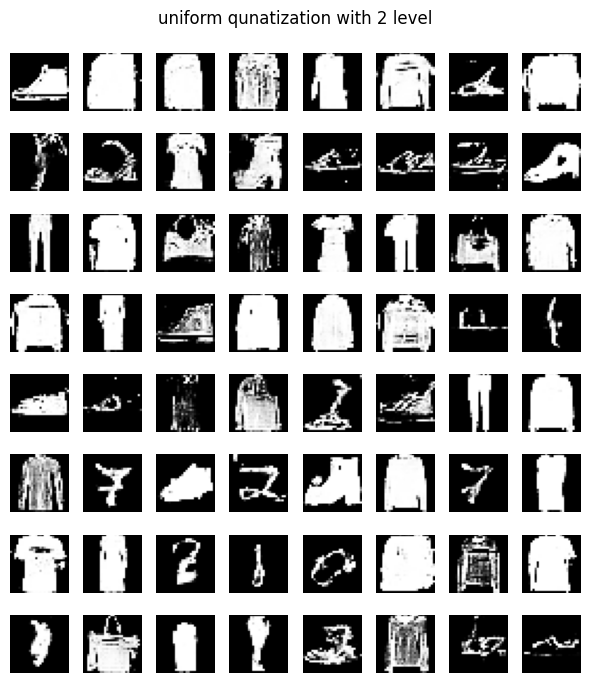

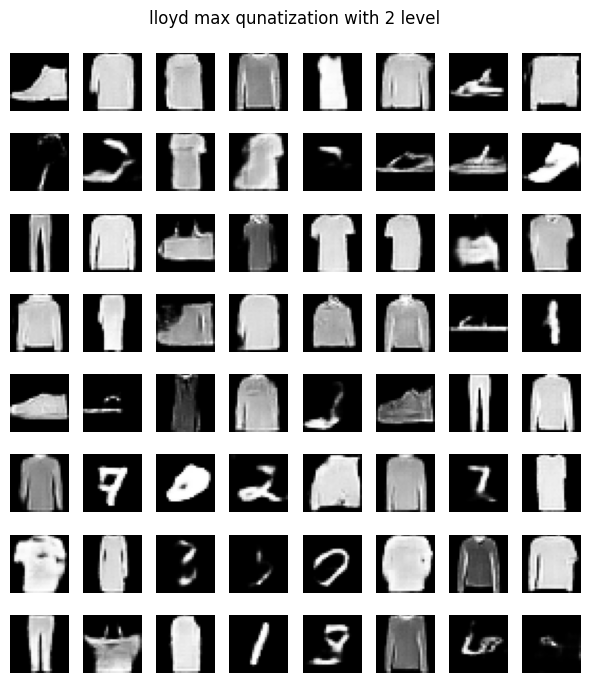

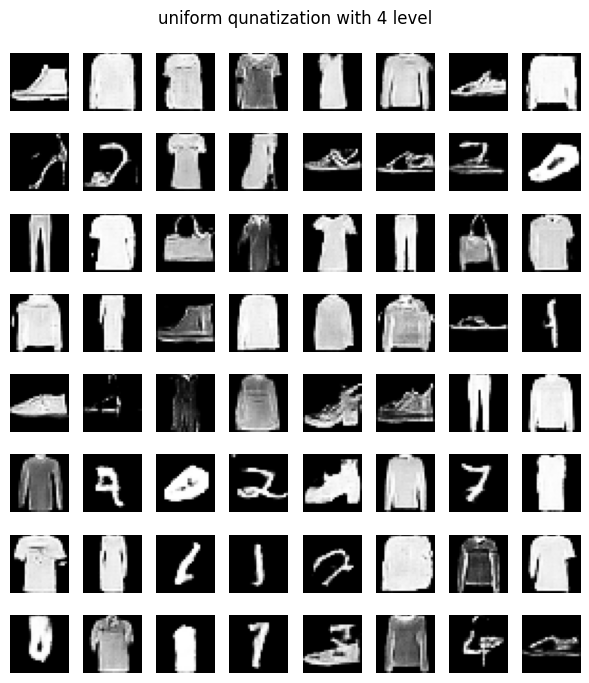

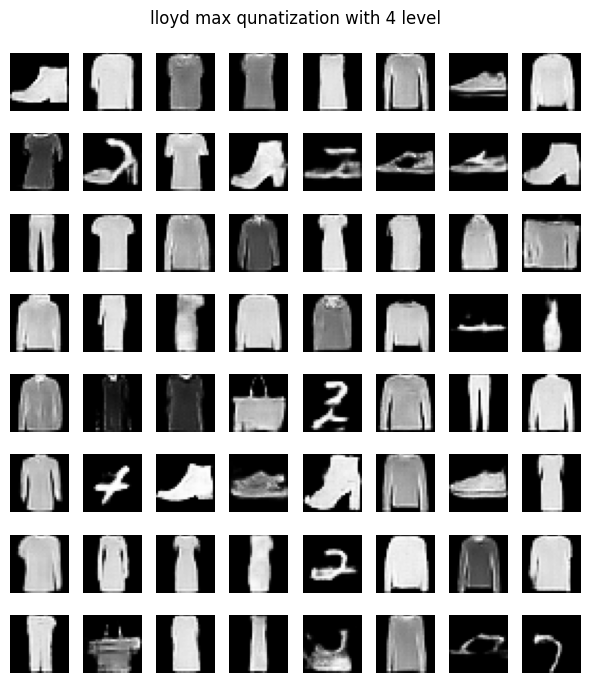

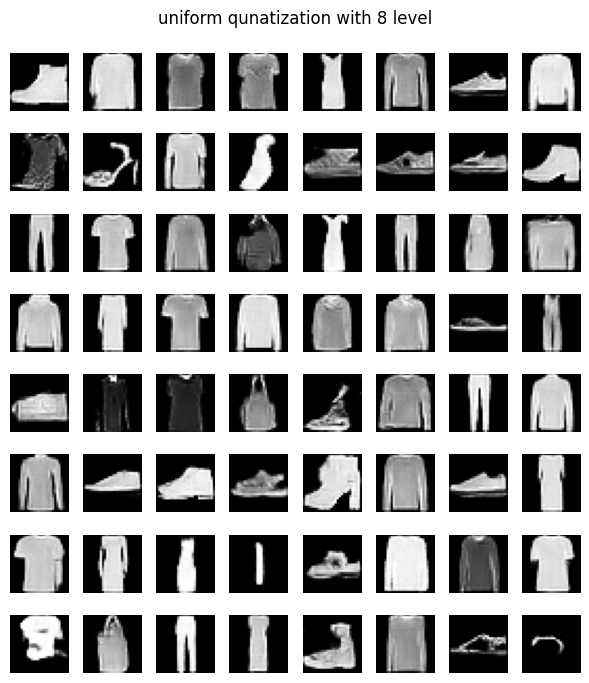

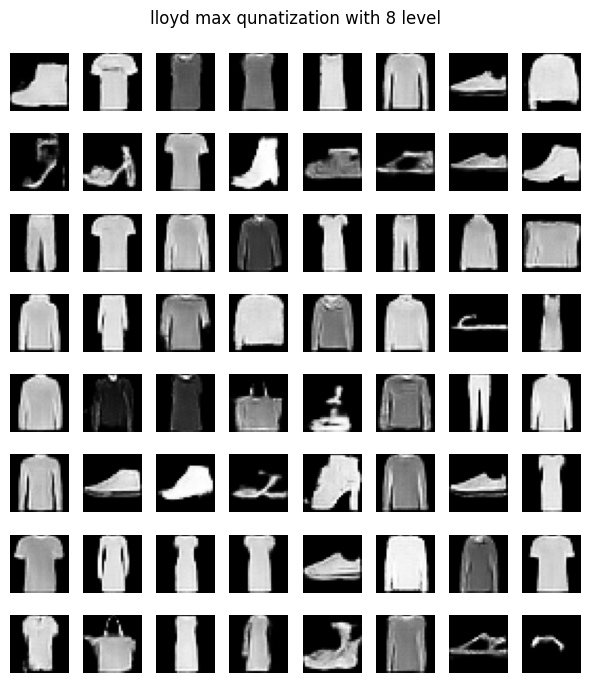

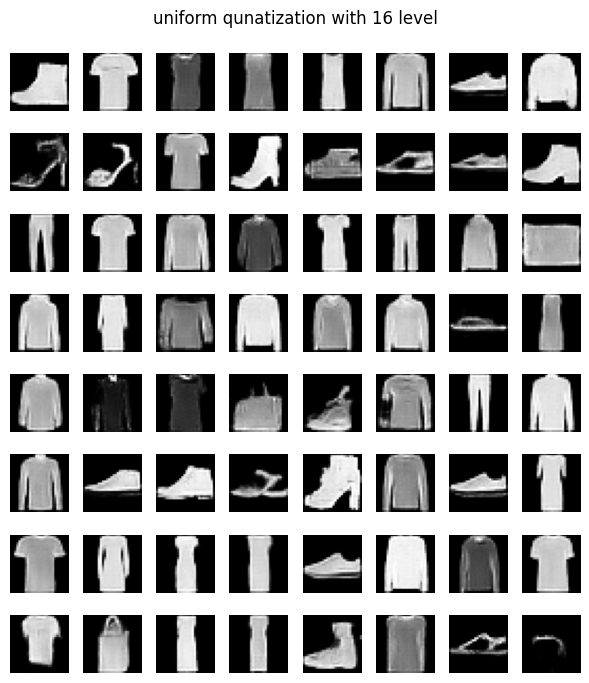

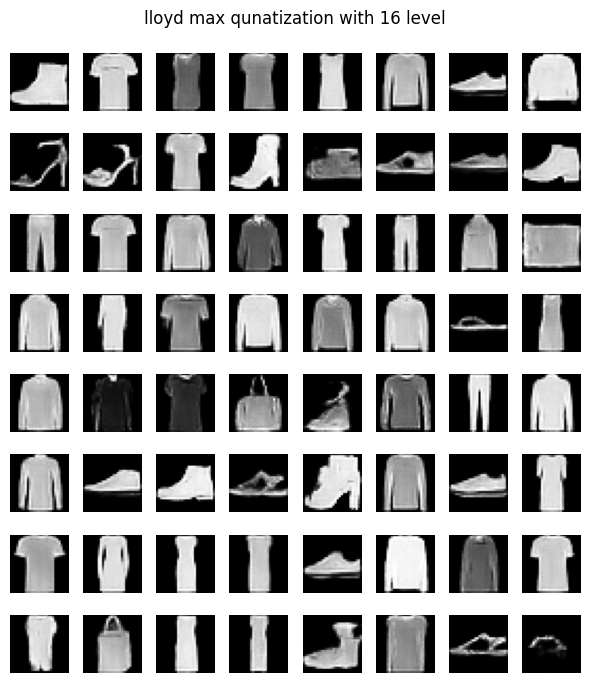

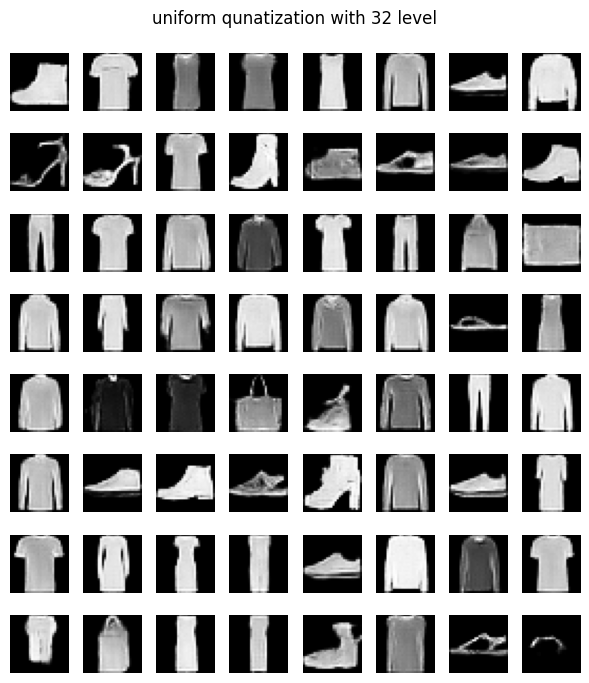

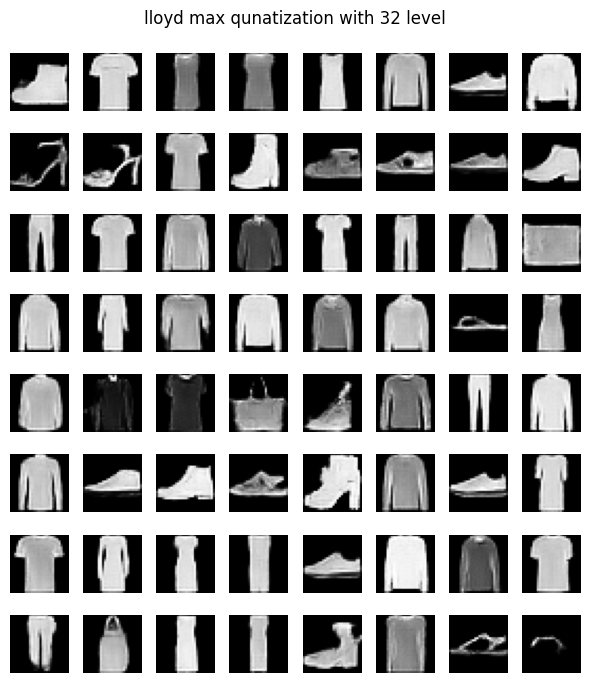

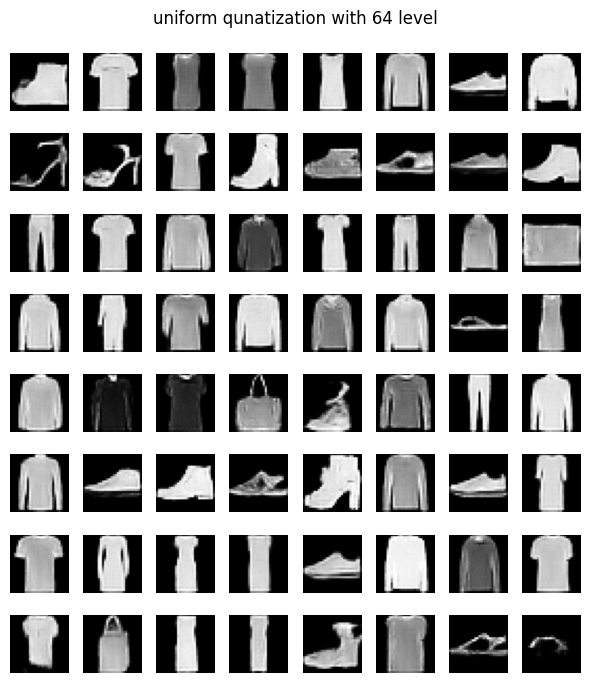

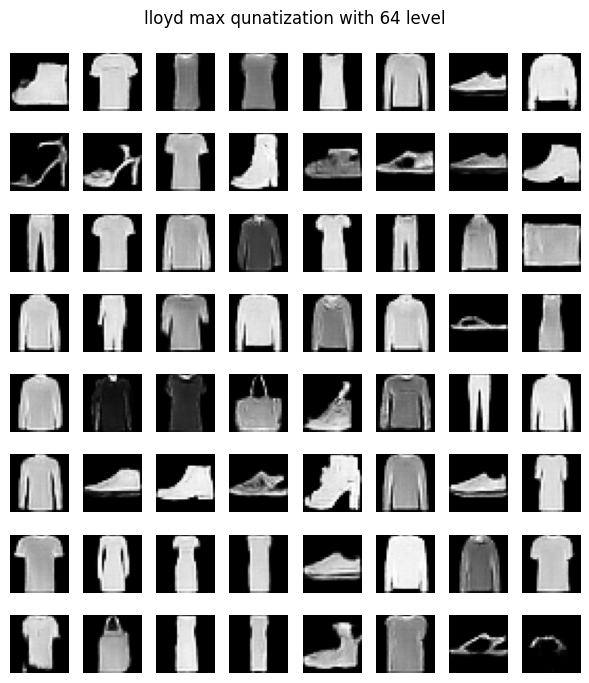

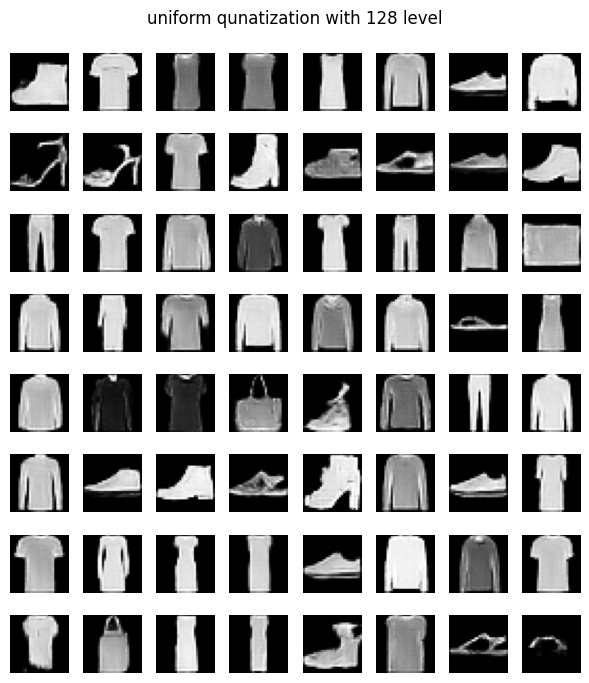

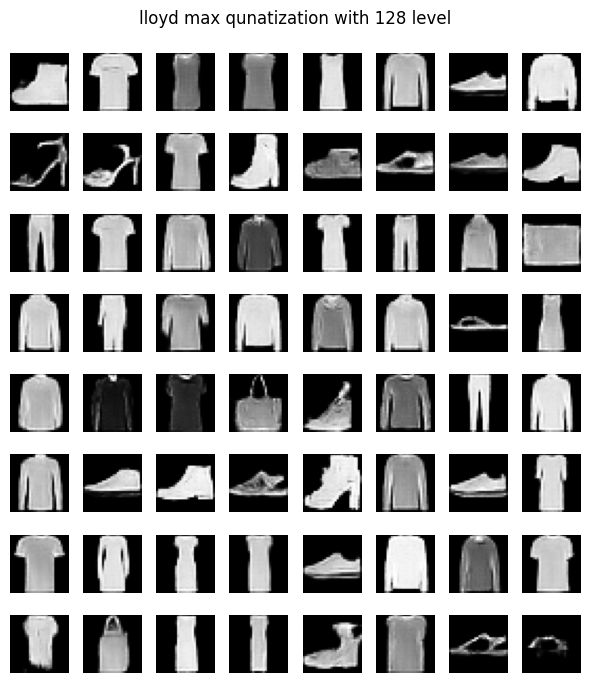

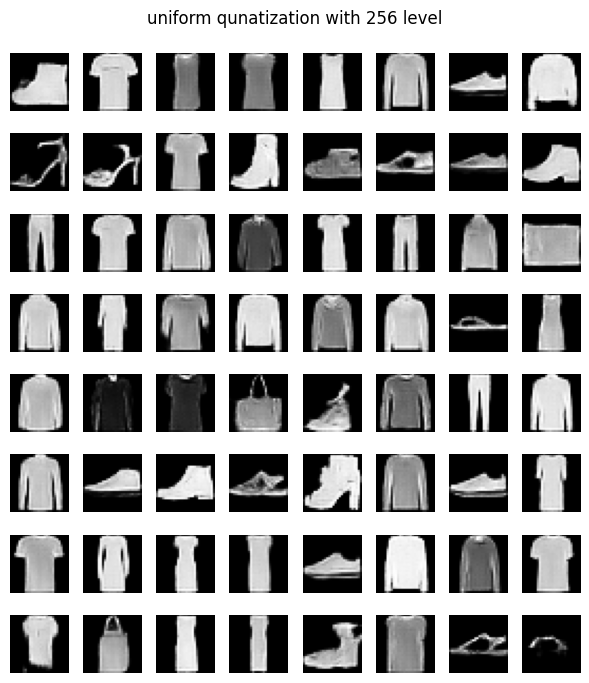

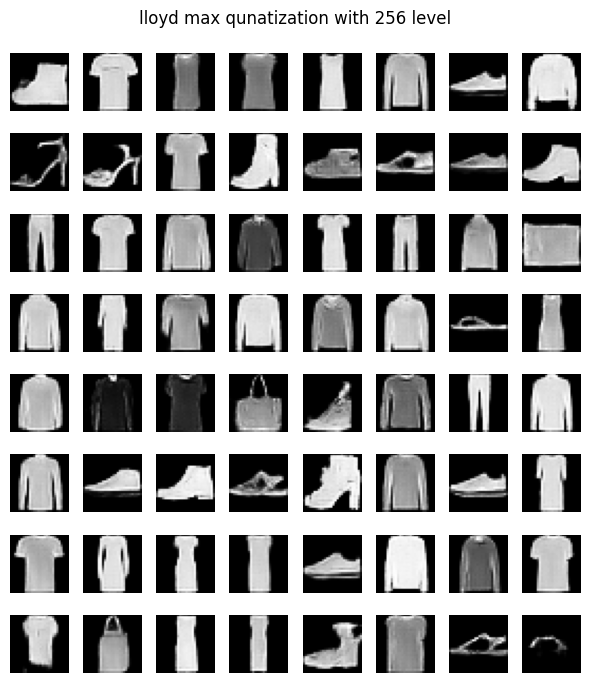

In [22]:
uni_mse = []
uni_psnr = []
uni_ssim = []
llo_mse = []
llo_psnr = []
llo_ssim = []
for i in range(1,9):
    bits = i
    print(bits)
    lloyd_max_codebook = torch.load(f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}_f.pth")
    # print(lloyd_max_codebook)
    q = lloyd_max_codebook["q"]
    b = lloyd_max_codebook["b"]
    
    z_q_uni, z_rec_uni, scale_uni = quantization(fixed_z,bits=bits)
    z_q_llo, z_rec_llo, _= quantization(fixed_z,type='lloyd',q=q,b=b)
    # print("uni")
    # print(z_q_uni)
    # print("lloyd")
    # print(z_q_llo)
    z_rec_uni = dequantization(z_q_uni,bits=bits)
    # print("uni")
    # print(z_rec_uni)
    z_rec_llo = dequantization(z_q_llo,type='lloyd',q=q)
    # print("lloyd")
    # print(z_rec_llo)
    z_rec_uni = z_rec_uni.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    z_rec_llo = z_rec_llo.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    with torch.no_grad():
        z_gen_uni = G(z_rec_uni)
        z_gen_llo = G(z_rec_llo)

    img = (x_gen_orig + 1) / 2
    img_uni = (z_gen_uni + 1) / 2
    img_llo = (z_gen_llo + 1) / 2
    print("=== Uniform ===")
    print("MSE:", mse(img, img_uni).item())
    print("PSNR:", psnr(img, img_uni).item())
    print("SSIM:", compute_ssim(img, img_uni).item())
    unimse = mse(img, img_uni).item()
    unipsnr = psnr(img, img_uni).item()
    unissim = compute_ssim(img, img_uni).item()
    uni_mse.append(unimse)
    uni_psnr.append(unipsnr)
    uni_ssim.append(unissim)
    print("\n=== Lloyd ===")
    print("MSE:", mse(img, img_llo).item())
    print("PSNR:", psnr(img, img_llo).item())
    print("SSIM:", compute_ssim(img, img_llo).item())
    unimse = mse(img, img_llo).item()
    unipsnr = psnr(img, img_llo).item()
    unissim = compute_ssim(img, img_llo).item()
    llo_mse.append(unimse)
    llo_psnr.append(unipsnr)
    llo_ssim.append(unissim)
    plt.figure(figsize=(6,7))
    for i in range(64):
        plt.subplot(8, 8, i+1)
        img = ((z_gen_uni[i] + 1) / 2).cpu().squeeze().numpy()
        plt.imshow(img, cmap='gray')
        plt.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.suptitle(f"uniform qunatization with {2**bits} level",fontsize=12)
    # plt.show()
    save_image((z_gen_uni.cpu() + 1) / 2, f"./save_data/lloyd_max_codebook/z_gen_uni_{2**bits}.png", nrow=8)

    plt.figure(figsize=(6,7))
    for i in range(64):
        plt.subplot(8, 8, i+1)
        img = ((z_gen_llo[i] + 1) / 2).cpu().squeeze().numpy()
        plt.imshow(img, cmap='gray')
        plt.axis("off")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.suptitle(f"lloyd max qunatization with {2**bits} level",fontsize=12)
    # plt.show()
    save_image((z_gen_llo.cpu() + 1) / 2, f"./save_data/lloyd_max_codebook/z_gen_lloyd_{2**bits}.png", nrow=8)

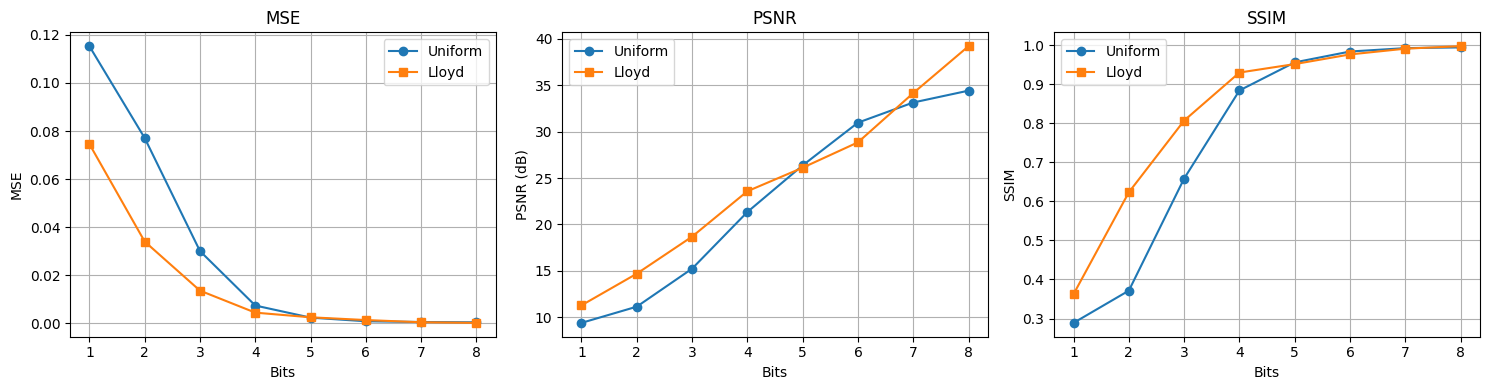

In [24]:
bits_list = list(range(1, 9))  # 你的 bits 範圍

plt.figure(figsize=(15, 4))

# ===== MSE =====
plt.subplot(1, 3, 1)
plt.plot(bits_list, uni_mse, marker='o', label='Uniform')
plt.plot(bits_list, llo_mse, marker='s', label='Lloyd')
plt.title("MSE")
plt.xlabel("Bits")
plt.ylabel("MSE")
plt.legend()
plt.grid()

# ===== PSNR =====
plt.subplot(1, 3, 2)
plt.plot(bits_list, uni_psnr, marker='o', label='Uniform')
plt.plot(bits_list, llo_psnr, marker='s', label='Lloyd')
plt.title("PSNR")
plt.xlabel("Bits")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.grid()

# ===== SSIM =====
plt.subplot(1, 3, 3)
plt.plot(bits_list, uni_ssim, marker='o', label='Uniform')
plt.plot(bits_list, llo_ssim, marker='s', label='Lloyd')
plt.title("SSIM")
plt.xlabel("Bits")
plt.ylabel("SSIM")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [18]:
# 做量化對還原的影響
# 從8bits到3bits 
# 大概到4bits的時候會有比較顯著的錯誤出現
# 統計結果是高斯分布 max在4 min是-4
# 2026.03.13

In [ ]:
E.eval()

bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

codebook_dir = f"./save_data/lloyd_max_codebook/lloyd_codebook_{bits}_f.pth"
codebook = torch.load(codebook_dir,
    map_location="cpu")
q = codebook["q"]
b = codebook["b"]
print(type(codebook))
print(codebook)

save_dir = F"./latent_bits_F/bits_{bits}/uni"
save_dir_llo = F"./latent_bits_F/bits_{bits}/llo"
save_dir_latent = F"./latent_bits_F/bits_{bits}/latent"
os.makedirs(save_dir, exist_ok=True)

dataset = dl.dataset
N = len(dataset)

for i,  (x, y) in enumerate(dl):
    print(i, x.shape, y.shape)
    print(y)
    x = x.to(device)
    # ------------------------
    # encode
    # ------------------------
    with torch.no_grad():
        mu, logvar = E(x)
        z = mu.squeeze(0)
    # # ------------------------
    # # quantization
    # # ------------------------
    z_q,_,_ = quantization (z,bits)
    z_q_lloyd,_,_ = quantization (z,bits,type="lloyd",q=q,b=b)

    # # ------------------------
    # # 轉 bit
    # # ------------------------
    bits_array = array_to_bits(z_q, bit_width=bits)
    bits_array_lloyd = array_to_bits(z_q_lloyd, bit_width=bits)
    #------------------------
    # 加上header
    # -----------------------
    idx_bits = np.array(list(f"{i:012b}"),dtype=np.float64)
    print("i=",i,'  ',idx_bits)
    dataset_bits = [1,1,1,1]
    loadbits_0 = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]
    loadbits_1 = [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]
    # 接到 bits 前面
    bits_with_idx = np.concatenate([idx_bits, dataset_bits, loadbits_0, idx_bits, dataset_bits, loadbits_0, bits_array])
    bits_with_idx_lloyd = np.concatenate([idx_bits, dataset_bits, loadbits_0, idx_bits, dataset_bits, loadbits_0, bits_array_lloyd])
   

    # ------------------------
    # 存 MAT
    # ------------------------
    # for j in range(mu.size(0)):

    #     z = mu[j]

    #     z_q, _, _ = quantization(z, bits)

    #     bits_array = array_to_bits(
    #         z_q,
    #         bit_width=bits
    #     )

    #     savemat(
    #         f"{save_dir}/sample_{i*64+j:05d}.mat",
    #         {"bits": bits_array.astype(np.float64)}
    #     )
    savemat(
        f"{save_dir}/sample_{i:05d}.mat",
        {"bits": bits_with_idx.astype(np.float64)}
    )
    savemat(
        f"{save_dir_llo}/sample_{i:05d}.mat",
        {"bits": bits_with_idx_lloyd.astype(np.float64)}
    )
    savemat(
            f"{save_dir_latent}/latent_{i:05d}.mat",
            {
                "id": np.array([i], dtype=np.int32),
                "latent": mu.detach().cpu().numpy(),
                "label": y.detach().cpu().numpy(),
            }
        )
    print(f"saved {i}")
print(i)

<class 'dict'>
{'q': tensor([-6.8110, -6.7568, -6.6828, -6.6485, -6.6145, -6.5505, -6.4832, -6.4307,
        -6.3763, -6.3265, -6.2638, -6.2132, -6.1510, -6.0918, -6.0479, -5.9994,
        -5.9395, -5.8898, -5.8232, -5.7672, -5.7168, -5.6612, -5.6113, -5.5576,
        -5.5025, -5.4491, -5.3978, -5.3477, -5.2943, -5.2347, -5.1728, -5.1218,
        -5.0673, -5.0149, -4.9563, -4.9006, -4.8412, -4.7860, -4.7403, -4.6861,
        -4.6395, -4.5906, -4.5388, -4.4883, -4.4316, -4.3756, -4.3183, -4.2664,
        -4.2076, -4.1461, -4.0911, -4.0322, -3.9776, -3.9262, -3.8703, -3.8165,
        -3.7626, -3.7046, -3.6447, -3.5899, -3.5381, -3.4853, -3.4337, -3.3797,
        -3.3265, -3.2740, -3.2226, -3.1675, -3.1108, -3.0567, -3.0002, -2.9436,
        -2.8907, -2.8363, -2.7827, -2.7298, -2.6749, -2.6196, -2.5650, -2.5112,
        -2.4566, -2.4031, -2.3490, -2.2943, -2.2399, -2.1845, -2.1293, -2.0756,
        -2.0213, -1.9678, -1.9142, -1.8603, -1.8064, -1.7524, -1.6988, -1.6443,
        -1.5896, -1

Exception in callback BaseAsyncIOLoop._handle_events(508, 1)
handle: <Handle BaseAsyncIOLoop._handle_events(508, 1)>
Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "d:\VAE_GAN_DM\venv\Lib\site-packages\tornado\platform\asyncio.py", line 208, in _handle_events
    handler_func(fileobj, events)
  File "d:\VAE_GAN_DM\venv\Lib\site-packages\zmq\eventloop\zmqstream.py", line 600, in _handle_events
    self._handle_recv()
  File "d:\VAE_GAN_DM\venv\Lib\site-packages\zmq\eventloop\zmqstream.py", line 629, in _handle_recv
    self._run_callback(callback, msg)
  File "d:\VAE_GAN_DM\venv\Lib\site-packages\zmq\eventloop\zmqstream.py", line 550, in _run_callback
    f = callback(*args, **kwargs)
        ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\VAE_GAN_DM\venv\Lib\site-packages\ipykernel\iostream.py", line 105, in _handle_subscription
    event_type = fram